# CLEAN on a simulated ALMA-like image

This notebook shows `virgil.radio_clean.clean`, virgil's Cotton–Schwab CLEAN for radio and millimetre visibilities, recovering a known sky. The sky is a ring, inclined like a protoplanetary disc, plus a compact clump outside it, a few hundred milliarcseconds across. We simulate complex visibilities on an interferometer-like uv track with thermal noise, form the dirty image and dirty beam, run CLEAN, and check the restored image against the truth in flux, position and noise level. By the end you should know how to call `clean`, what its result holds, and how to tell that it worked.

Everything is synthetic and seeded, and the whole notebook runs in about twenty seconds on a laptop. The package is provisional, so details may change before it settles; the [guide](radio_clean.md) maps its arguments to CASA's `tclean`.

We start by building the truth and the data. The truth is a pixel image on a 129 × 129 grid of 4 mas pixels, so the field of view is 516 mas: an inclined Gaussian ring of radius 100 mas holding 0.8 Jy, and a small Gaussian clump 6 mas wide holding 0.2 Jy to its north-east. The observation has 80 random baselines between 100 m and 10 km at 1.3 mm, tracked for six hours from a southern site towards a source at declination −37°, which gives 4,800 uv points out to about 7.6 megawavelengths. The visibilities are the exact transform of the truth plus Gaussian noise of 0.02 Jy per real and imaginary part. They go into a `ComplexVisData`, the container that every `virgil.radio` tool takes.

In [1]:
import numpy as onp
import matplotlib.pyplot as plt
from virgil import scenes
from virgil._geometry import image_visibilities
from virgil.radio import ComplexVisData

N, S, SIG = 129, 4.0, 0.02                      # pixels, mas per pixel, Jy per real/imag part
truth = onp.asarray(0.8 * scenes.ring(N, S, 100, 14, inc_deg=50, pa_deg=40) + 0.2 * scenes.gaussian_blob(N, S, 6, dra=170, ddec=110))
rng = onp.random.default_rng(1)
bl = onp.exp(rng.uniform(onp.log(100), onp.log(1e4), (80, 2))) * rng.choice([-1, 1], (80, 2))   # east, north (m)
H, dec, lat = onp.deg2rad(onp.linspace(-45, 45, 60)), onp.deg2rad(-37), onp.deg2rad(-23)
u = ((bl[:, :1] * onp.cos(H) - bl[:, 1:] * onp.sin(lat) * onp.sin(H)) / 1.3e-3).ravel()
v = ((bl[:, :1] * onp.sin(dec) * onp.sin(H) + bl[:, 1:] * (onp.sin(lat) * onp.sin(dec) * onp.cos(H) + onp.cos(lat) * onp.cos(dec))) / 1.3e-3).ravel()
vis = onp.asarray(image_visibilities(truth, u, v, S, ft="dft")) + SIG * (rng.normal(size=u.size) + 1j * rng.normal(size=u.size))
data = ComplexVisData.from_arrays(u, v, vis, 1 / SIG**2, 230e9)
print(f"{len(data)} visibilities, longest baseline {onp.hypot(u, v).max() / 1e6:.1f} Mλ, true flux {truth.sum():.2f} Jy")

4800 visibilities, longest baseline 7.6 Mλ, true flux 1.00 Jy


Before deconvolving, it helps to see what the data alone give. `ComplexVisData.dirty_image` is the inverse transform of the visibilities onto the pixel grid, in Jy per beam, and `dirty_beam` is the same transform of a unit point source at the phase centre: the point-spread function (PSF) that every source is convolved with. With only 4,800 points the PSF has strong sidelobes, and these are what CLEAN will remove. The left panel is the dirty image and the right panel is the dirty beam. The cyan plus marks the clump's true position; East is to the left and North is up, as in every sky image in virgil, so the clump should sit in the upper left.

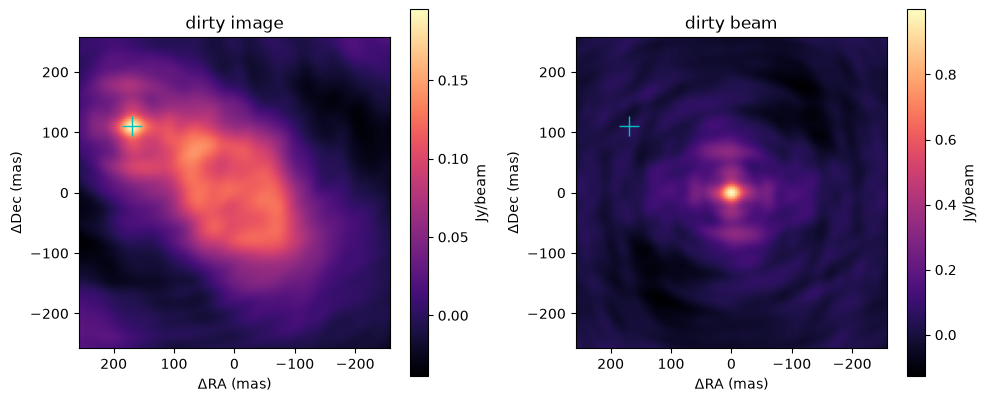

In [2]:
dirty = data.dirty_image(N, S)                  # Jy/beam, row 0 = North, column 0 = East
psf = data.dirty_beam(N, S)                     # peak 1 at the phase centre
half = N * S / 2
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, im, title in zip(axes, (dirty, psf), ("dirty image", "dirty beam")):
    shown = ax.imshow(im, extent=[half, -half, -half, half], origin="upper", cmap="magma")
    ax.plot(170, 110, "c+", ms=14)
    ax.set(xlabel="ΔRA (mas)", ylabel="ΔDec (mas)", title=title)
    fig.colorbar(shown, ax=ax, label="Jy/beam")
fig.tight_layout()

Now we run CLEAN. We ask for the multi-scale deconvolver, because the ring is extended: besides point components it may place Gaussian components 4 and 12 pixels wide, which describe a smooth ring with far fewer components than points would. We stop at three times the thermal noise in the image, which for natural weighting is `1/sqrt(Σw)`, about 0.29 mJy/beam here, and `usemask="auto-multithresh"` lets CLEAN find where the emission is instead of being told. Each major cycle recomputes the residual from the visibilities themselves, `V − M` with `M` the transform of the model, so the sidelobe errors of the minor cycles do not accumulate. The result reports why it stopped, how many components it placed, and the restoring beam it fitted to the dirty beam's core.

In [3]:
from virgil.radio_clean import clean

sigma_img = 1 / onp.sqrt(onp.sum(onp.asarray(data.weight)))     # thermal noise of the natural-weighted image
res = clean(data, N, S, deconvolver="multiscale", scales=[0, 4, 12], niter=5000,
            threshold=3 * sigma_img, usemask="auto-multithresh")
bmaj, bmin, pa = res.beam
print(f"stopped on '{res.stop}' after {res.iterations} iterations in {len(res.history)} major cycles; "
      f"beam {bmaj:.0f} x {bmin:.0f} mas at PA {pa:.0f} deg")

stopped on 'threshold' after 742 iterations in 6 major cycles; beam 47 x 45 mas at PA 93 deg


The restored image is the CLEAN model convolved with the fitted beam, plus the final residual, so that the noise keeps its true level. We compare it with the truth convolved with the same beam, which is what a perfect CLEAN would give, in four panels. The first is the true sky and the second is the restored CLEAN image with the beam drawn as a shaded ellipse in the lower-left corner, well clear of the sources. The third is the residual image that CLEAN leaves behind, which should look like noise; the fourth is the restored image minus the beam-convolved truth. Neither residual map has uncertainties attached, so both are plain signed residuals in Jy/beam, not z-scores. The first two panels use a square-root colour scale so that the faint ring is visible next to the clump. The cyan plus marks the clump's true position in every panel.

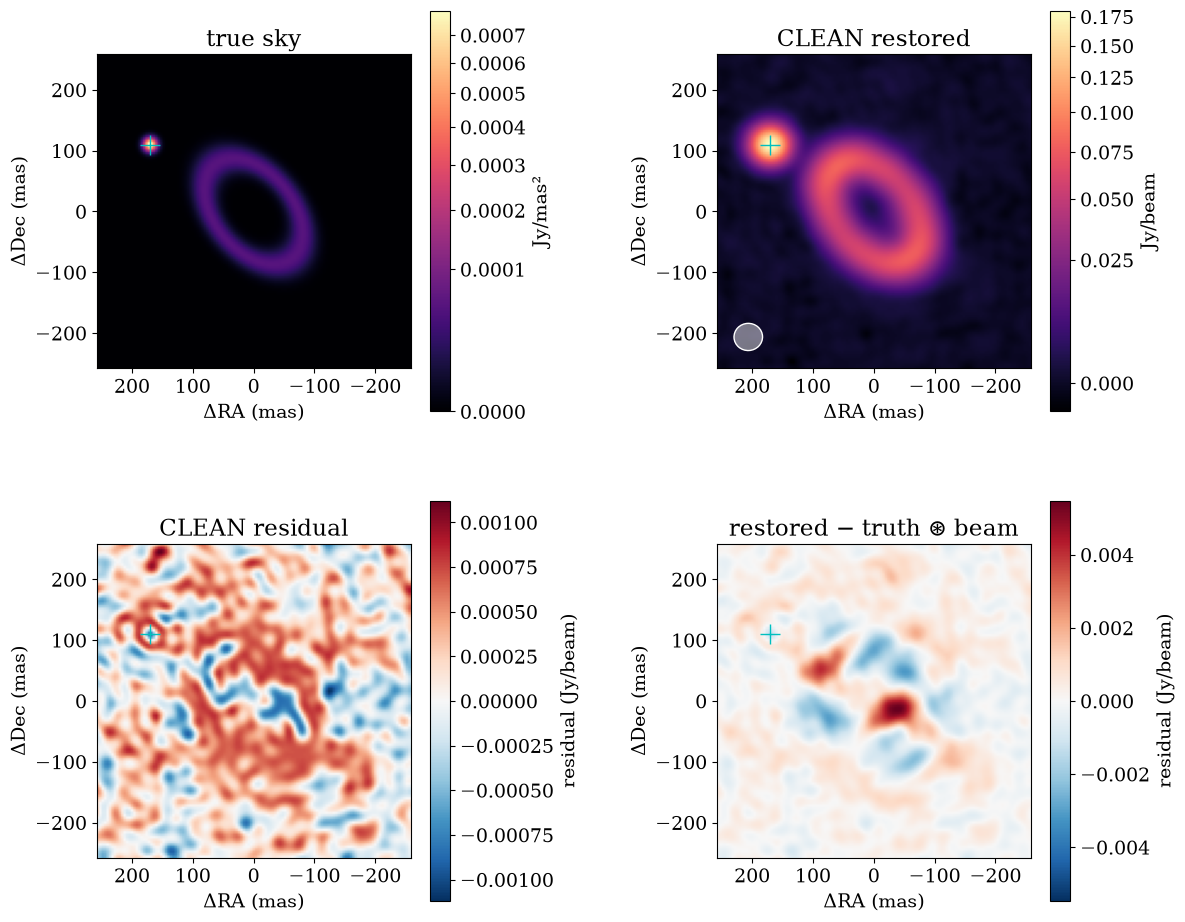

In [4]:
from matplotlib.colors import PowerNorm
from virgil.imaging import Beam
from virgil.plotting import _draw_beam, _style_context, plot_residual_map
from virgil.radio_clean import restore

beam = Beam(bmaj, bmin, pa)
ideal = restore(truth, onp.zeros_like(truth), res.beam, S)     # the truth seen through the same beam
with _style_context():                           # the style plot_residual_map applies, for every panel
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for ax, im, title in zip(axes.flat[:2], (truth / S**2, res.image), ("true sky", "CLEAN restored")):
        shown = ax.imshow(im, extent=[half, -half, -half, half], origin="upper", cmap="magma", norm=PowerNorm(0.5))
        ax.set(xlabel="ΔRA (mas)", ylabel="ΔDec (mas)", title=title)
        fig.colorbar(shown, ax=ax, label="Jy/mas²" if im is not res.image else "Jy/beam")
    _draw_beam(axes[0, 1], beam)
    for ax, im, title in zip(axes.flat[2:], (res.residual, res.image - ideal), ("CLEAN residual", "restored − truth ⊛ beam")):
        plot_residual_map(im, N * S, ax=ax, title=title)
        fig.axes[-1].set_ylabel("residual (Jy/beam)")
    for ax in axes.flat:
        ax.plot(170, 110, "c+", ms=14)
    fig.tight_layout(w_pad=3)

Pictures can flatter, so here are the numbers. Because CLEAN's model should carry the sky's total flux, we compare the recovered and true flux. We compare where the brightest pixel of the restored image falls against where it falls in the ideal image, to check the orientation and the pixel grid, and we compare the rms of the CLEAN residual image with the thermal noise we computed from the weights. The residual should sit a little above the thermal level, since the model is not perfect, but of the same order; a residual many times the noise would mean that CLEAN stopped early or failed.

In [5]:
def peak(im):
    row, col = onp.unravel_index(onp.argmax(im), im.shape)
    return float((N - 1) / 2 * S - col * S), float((N - 1) / 2 * S - row * S)   # (ΔRA, ΔDec) in mas, East positive
print(f"flux: recovered {res.model.sum():.4f} Jy, true {truth.sum():.4f} Jy\n"
      f"peak (ΔRA, ΔDec) in mas: CLEAN {peak(res.image)}, ideal {peak(ideal)}\n"
      f"residual rms {1e3 * onp.std(res.residual):.3f} mJy/beam, thermal σ {1e3 * sigma_img:.3f} mJy/beam")

flux: recovered 0.9975 Jy, true 1.0000 Jy
peak (ΔRA, ΔDec) in mas: CLEAN (172.0, 108.0), ideal (168.0, 112.0)
residual rms 0.363 mJy/beam, thermal σ 0.289 mJy/beam


Finally we check the fit in the visibility plane, which is where the data live. `RadioCleanResult.model_visibilities` gives the CLEAN model's visibilities at the observed (u, v) points, using the same transform as the major cycles. Plotted against the data, the real and imaginary parts should fall on the one-to-one line, scattered by the noise alone, over the full range from the large short-baseline fluxes to the faint long-baseline ones. Error bars are the 0.02 Jy noise; virgil's `plot_data_model_correlation` is written for optical-interferometry observables, so this cell draws the same plot for complex visibilities directly.

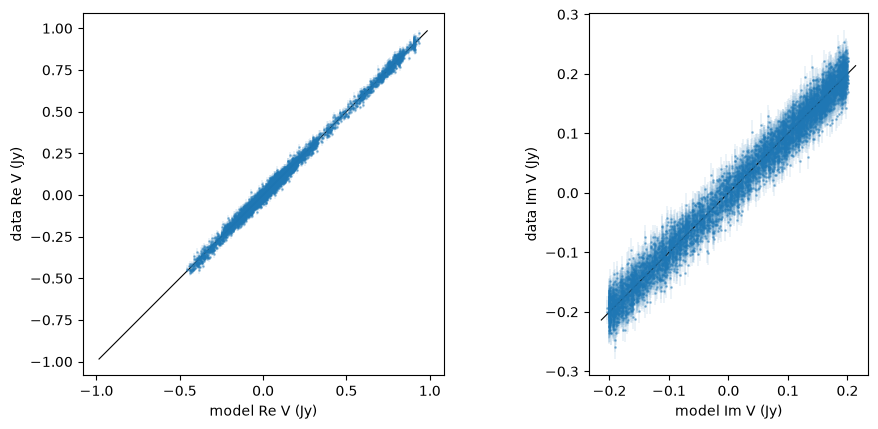

In [6]:
model_vis = res.model_visibilities(data)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, part, name in zip(axes, (onp.real, onp.imag), ("Re V", "Im V")):
    x, y = part(model_vis), part(onp.asarray(data.vis))
    ax.errorbar(x, y, yerr=SIG, fmt=".", ms=2, elinewidth=0.3, alpha=0.4)
    lim = 1.05 * onp.abs(x).max()
    ax.plot([-lim, lim], [-lim, lim], "k-", lw=0.8)
    ax.set(xlabel=f"model {name} (Jy)", ylabel=f"data {name} (Jy)", aspect="equal")
fig.tight_layout()

CLEAN recovered the simulated sky: the stopping rule fired at three times the thermal noise, the recovered flux and peak position match the truth, the residual image is noise-like and close to the thermal level, and the model's visibilities lie on the data's one-to-one line. The restored image is the model smoothed by the beam, so it is a deliberately blurred picture with the noise honestly included, and sub-beam details such as the exact ring width cannot be read from it. To apply this to a real measurement set, build the `ComplexVisData` with `ComplexVisData.read_ms`, set `weighting="briggs"` with a `robust` value, optionally a `uvtaper`, and write the products with `res.write_fits`. See the [guide](radio_clean.md) for the arguments and their `tclean` and WSClean equivalents.